In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

hist = pd.read_csv("/Users/famousck/risk_management/ercot_generator_hedge_project/outputs/five_year_historical_backtest.csv")
fwd = pd.read_csv("/Users/famousck/risk_management/ercot_generator_hedge_project/outputs/two_year_forward_hedge_plan.csv")

In [33]:
price_paths = np.load("/Users/famousck/risk_management/ercot_generator_hedge_project/outputs/sim_price_paths.npy")
df = pd.read_csv("/Users/famousck/risk_management/ercot_generator_hedge_project/data/processed/hb_north_with_gas.csv")
df["datetime"] = pd.to_datetime(df["datetime"])
hist_prices = df["price"]
sim_prices = price_paths.flatten()

In [34]:
sim_sample = np.random.default_rng(42).choice(
    price_paths.flatten(),
    size=750_000,
    replace=False
)

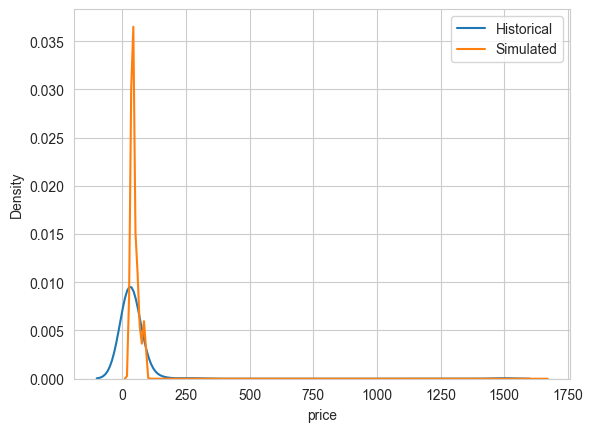

In [35]:
hours_per_month = 720
n_months = 24

sim_monthly_avg = np.column_stack([
    price_paths[:, i*hours_per_month:(i+1)*hours_per_month].mean(axis=1)
    for i in range(n_months)
]).flatten()

hist_monthly_avg = (
    df.groupby(df["datetime"].dt.to_period("M"))["price"]
    .mean()
)

sns.kdeplot(hist_monthly_avg, label="Historical")
sns.kdeplot(sim_monthly_avg, label="Simulated")
plt.legend()

In [36]:
print("Historical monthly:")
print(hist_monthly_avg.describe())

print("Simulated monthly:")
print(pd.Series(sim_monthly_avg).describe())

Historical monthly:
count     185.000000
mean       42.646011
std       109.651217
min        14.429052
25%        23.305478
50%        29.351157
75%        35.770605
max      1485.491503
Name: price, dtype: float64
Simulated monthly:
count    240000.000000
mean         47.673746
std          19.893470
min          14.244078
25%          36.384353
50%          42.746760
75%          54.639794
max        1665.559653
dtype: float64


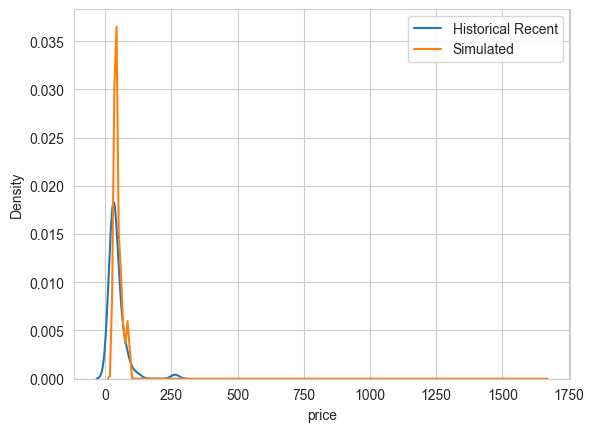

In [37]:
recent = df[df["datetime"] >= df["datetime"].max() - pd.DateOffset(years=5)]

hist_monthly_avg_recent = (
    recent.groupby(recent["datetime"].dt.to_period("M"))["price"].mean()
    .mean()
)

hist_monthly_avg_recent = (
    recent.groupby(recent["datetime"].dt.to_period("M"))["price"].mean()
)

sns.kdeplot(hist_monthly_avg_recent, label="Historical Recent")
sns.kdeplot(sim_monthly_avg, label="Simulated")
plt.legend()

In [38]:
summary = hist.groupby("strike_quantile").agg({
    "unhedged_profit": "mean",
    "hedged_profit": "mean",
    "profit_change": "mean"
}).reset_index()

print(summary)

   strike_quantile  unhedged_profit  hedged_profit  profit_change
0             0.25     1.791288e+07   1.869150e+07  778617.393550
1             0.50     1.791288e+07   1.884815e+07  935266.583309
2             0.60     1.791288e+07   1.795471e+07   41825.877163
3             0.75     1.791288e+07   1.848259e+07  569702.474227


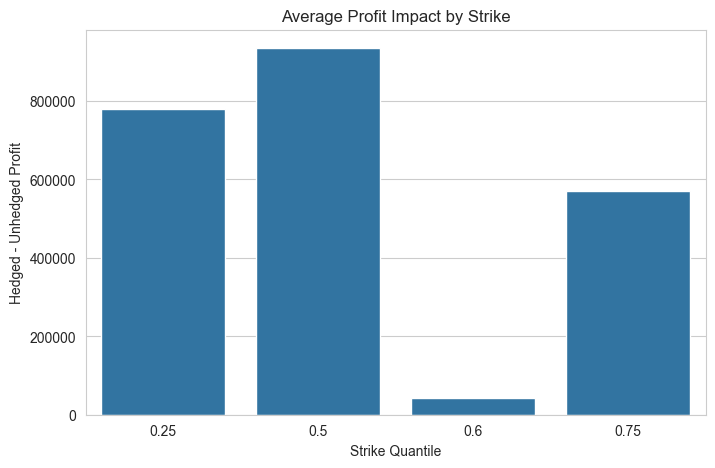

In [39]:
plt.figure(figsize=(8,5))
sns.barplot(data=summary, x="strike_quantile", y="profit_change")
plt.title("Average Profit Impact by Strike")
plt.ylabel("Hedged - Unhedged Profit")
plt.xlabel("Strike Quantile")
plt.show()

In [40]:
def es5(x):
    var5 = x.quantile(0.05)
    return x[x <= var5].mean()

risk = hist.groupby("strike_quantile").agg({
    "unhedged_profit": es5,
    "hedged_profit": es5
}).reset_index()

risk["improvement"] = risk["hedged_profit"] - risk["unhedged_profit"]
print(risk)

   strike_quantile  unhedged_profit  hedged_profit    improvement
0             0.25    835852.193728   1.523707e+06  687855.175263
1             0.50    835852.193728   1.526994e+06  691141.326017
2             0.60    835852.193728   1.215262e+06  379409.656251
3             0.75    835852.193728   1.439868e+06  604016.138404


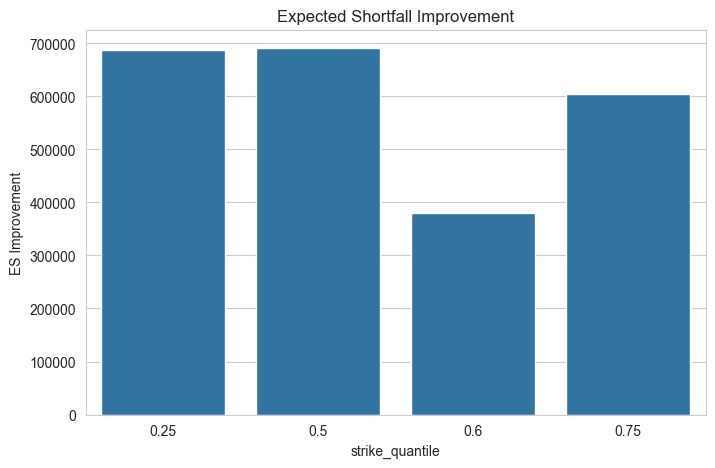

In [41]:
plt.figure(figsize=(8,5))
sns.barplot(data=risk, x="strike_quantile", y="improvement")
plt.title("Expected Shortfall Improvement")
plt.ylabel("ES Improvement")
plt.show()

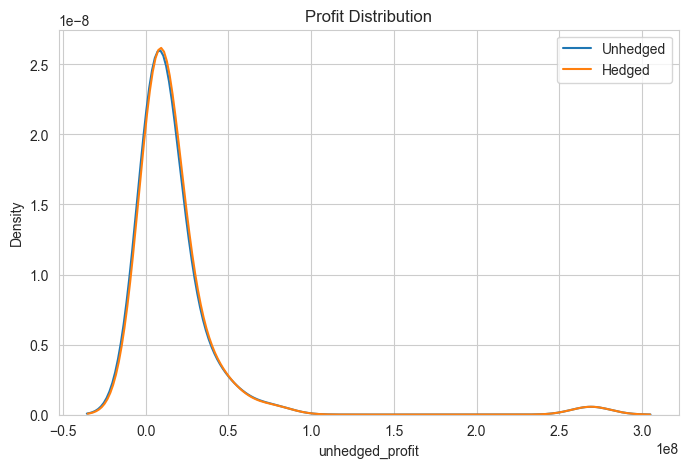

In [42]:
plt.figure(figsize=(8,5))
sns.kdeplot(hist["unhedged_profit"], label="Unhedged")
sns.kdeplot(hist["hedged_profit"], label="Hedged")
plt.title("Profit Distribution")
plt.legend()
plt.show()

In [43]:
fwd_summary = fwd.groupby("strike_percentile").agg({
    "mean_profit_change": "mean",
    "variance_reduction": "mean",
    "es5_improvement": "mean"
}).reset_index()

print(fwd_summary)

   strike_percentile  mean_profit_change  variance_reduction  es5_improvement
0                 25         1491.871195            0.022370     5.678795e+05
1                 50         3865.730831            0.040803     8.303877e+05
2                 60         5152.648478            0.047576     9.092966e+05
3                 75         7607.559509            0.056846     1.009302e+06


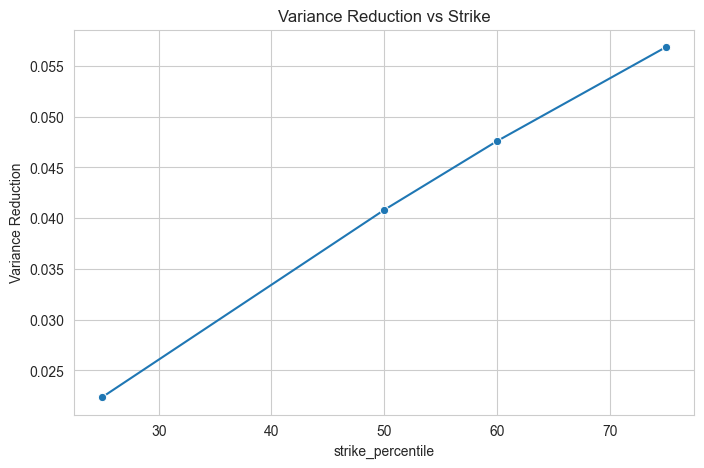

In [44]:
plt.figure(figsize=(8,5))
sns.lineplot(data=fwd_summary, x="strike_percentile", y="variance_reduction", marker="o")
plt.title("Variance Reduction vs Strike")
plt.ylabel("Variance Reduction")
plt.show()

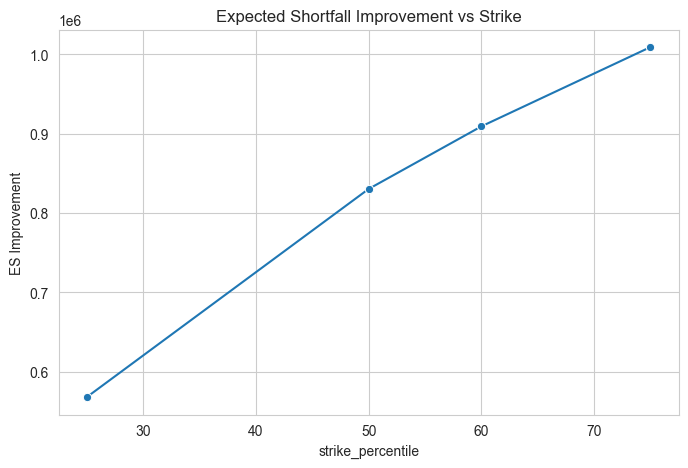

In [45]:
plt.figure(figsize=(8,5))
sns.lineplot(data=fwd_summary, x="strike_percentile", y="es5_improvement", marker="o")
plt.title("Expected Shortfall Improvement vs Strike")
plt.ylabel("ES Improvement")
plt.show()

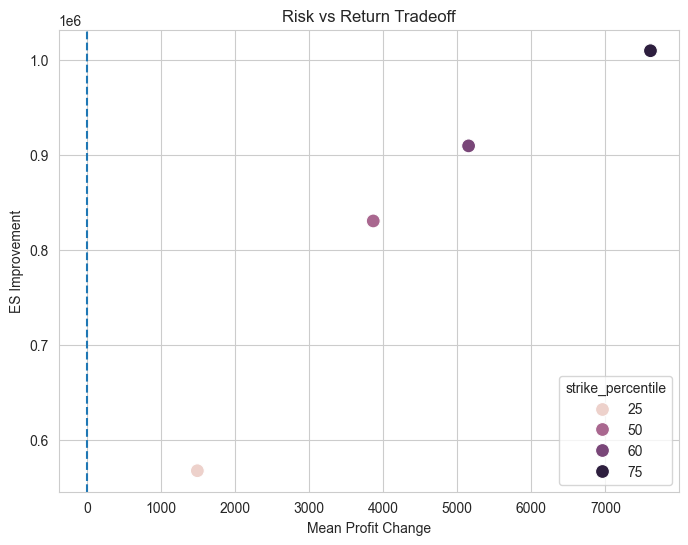

In [48]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=fwd_summary,
    x="mean_profit_change",
    y="es5_improvement",
    hue="strike_percentile",
    s=100
)

plt.axvline(0, linestyle="--")
plt.title("Risk vs Return Tradeoff")
plt.xlabel("Mean Profit Change")
plt.ylabel("ES Improvement")
plt.show()

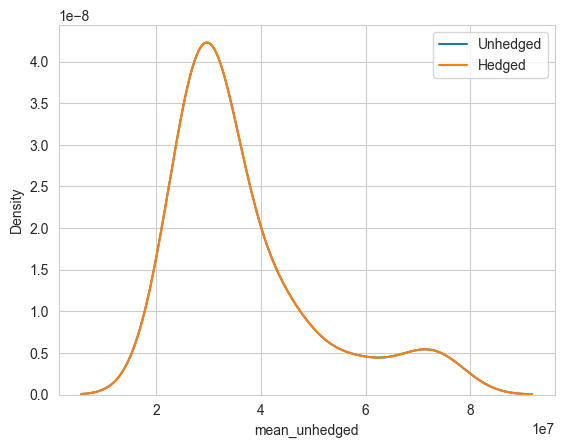

In [50]:
sns.kdeplot(fwd["mean_unhedged"], label="Unhedged")
sns.kdeplot(fwd["mean_hedged"], label="Hedged")
plt.legend()

In [51]:
fwd.groupby("strike_percentile").agg({
    "mean_profit_change": "mean",
    "variance_reduction": "mean",
    "es5_improvement": "mean"
})

,mean_profit_change,variance_reduction,es5_improvement
strike_percentile,,,
25,1491.871195,0.022370,5.678795e+05
50,3865.730831,0.040803,8.303877e+05
60,5152.648478,0.047576,9.092966e+05
75,7607.559509,0.056846,1.009302e+06


<Axes: xlabel='strike_percentile', ylabel='es5_improvement'>

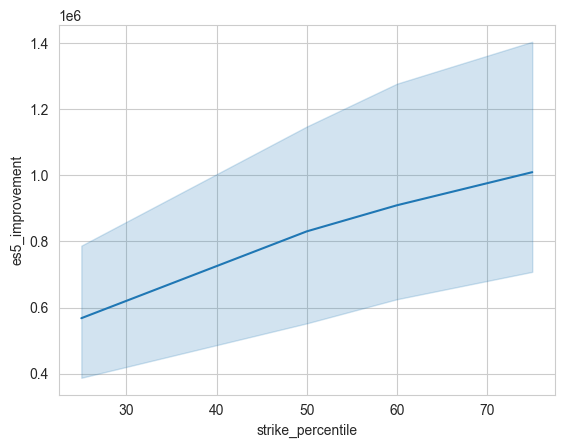

In [52]:
sns.lineplot(data=fwd, x="strike_percentile", y="es5_improvement")

<Axes: xlabel='mean_profit_change', ylabel='es5_improvement'>

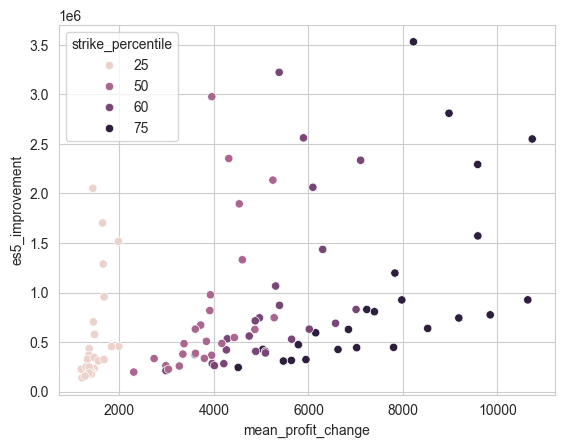

In [53]:
sns.scatterplot(
    data=fwd,
    x="mean_profit_change",
    y="es5_improvement",
    hue="strike_percentile"
)

In [49]:
hist["year"] = pd.to_datetime(hist["month"]).dt.year

# Define regimes
hist["regime"] = pd.cut(
    hist["avg_price"],
    bins=[0, 30, 50, 100],
    labels=["Low", "Medium", "High"]
)

hist.groupby(["regime", "strike_quantile"]).agg({
    "profit_change": "mean",
    "hedged_profit": "mean"
})

/var/folders/nh/jwyv82sx4714gg9tkhxfg8600000gn/T/ipykernel_8496/389440823.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hist.groupby(["regime", "strike_quantile"]).agg({


profit_change  hedged_profit
regime strike_quantile                              
Low    0.25              2.179869e+06   7.131559e+06
       0.50              2.687559e+06   7.639249e+06
       0.60              1.222037e+05   5.073894e+06
       0.75              1.649135e+06   6.600826e+06
Medium 0.25              3.614634e+04   1.086018e+07
       0.50             -1.241293e+04   1.081162e+07
       0.60             -2.181250e+03   1.082186e+07
       0.75              1.973888e+05   1.102143e+07
High   0.25              0.000000e+00   3.049598e+07
       0.50             -3.082477e-01   3.049598e+07
       0.60             -6.647162e-01   3.049598e+07
       0.75             -5.581736e+05   2.993781e+07

In [23]:
def es5(x):
    var5 = x.quantile(0.05)
    return x[x <= var5].mean()

print("VaR (5%):", hist["unhedged_profit"].quantile(0.05))
print("ES (5%):", es5(hist["unhedged_profit"]))

VaR (5%): 1558638.0590187525
ES (5%): 835852.1937284027


In [25]:
summary = hist.groupby("strike_quantile").agg({
    "profit_change": "mean",
    "premium_paid": "mean"
})

summary

,profit_change,premium_paid
strike_quantile,,
0.25,778617.393550,2.978008e-07
0.50,935266.583309,1.569524e+04
0.60,41825.877163,2.220767e+04
0.75,569702.474227,3.221507e+05


Text(0, 0.5, 'Profit Change')

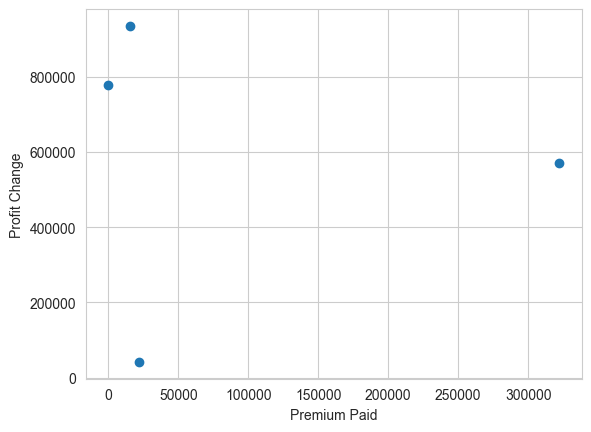

In [26]:
plt.scatter(summary["premium_paid"], summary["profit_change"])
plt.xlabel("Premium Paid")
plt.ylabel("Profit Change")

In [58]:
fwd

,forward_month,strike_percentile,strike,premium_per_mwh,optimal_hedge_ratio,base_notional_mwh,mean_unhedged,mean_hedged,mean_profit_change,std_unhedged,std_hedged,var5_unhedged,var5_hedged,var5_improvement,es5_unhedged,es5_hedged,es5_improvement,prob_loss_unhedged,prob_loss_hedged,variance_reduction
0,1,25,40.795793,0.585820,0.999994,744663.234906,3.228351e+07,3.228495e+07,1436.561073,1.543161e+07,1.531385e+07,2.644721e+07,2.797083e+07,1.523620e+06,2.524621e+07,2.729800e+07,2.051793e+06,0.0000,0.0000,0.015203
1,1,50,43.583803,1.612467,0.999994,744663.234906,3.228351e+07,3.228746e+07,3954.128361,1.543161e+07,1.520218e+07,2.644721e+07,2.880621e+07,2.359009e+06,2.524621e+07,2.822278e+07,2.976569e+06,0.0000,0.0000,0.029514
2,1,60,44.642558,2.194059,0.999994,744663.234906,3.228351e+07,3.228889e+07,5380.318928,1.543161e+07,1.515870e+07,2.644721e+07,2.902672e+07,2.579512e+06,2.524621e+07,2.846868e+07,3.222469e+06,0.0000,0.0000,0.035057
3,1,75,46.357935,3.353168,0.999994,744663.234906,3.228351e+07,3.229173e+07,8222.712102,1.543161e+07,1.509432e+07,2.644721e+07,2.935165e+07,2.904448e+06,2.524621e+07,2.877709e+07,3.530875e+06,0.0000,0.0000,0.043237
4,2,25,49.629594,0.607284,0.999994,821653.274477,3.931873e+07,3.932038e+07,1643.162716,1.408204e+07,1.392151e+07,3.218260e+07,3.347514e+07,1.292535e+06,3.058637e+07,3.228822e+07,1.701849e+06,0.0000,0.0000,0.022669
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,23,75,32.310759,3.337295,0.677691,606015.224784,2.332179e+07,2.332630e+07,4513.489813,1.255924e+07,1.234325e+07,1.106915e+07,1.155585e+07,4.866956e+05,7.722486e+06,7.966577e+06,2.440913e+05,0.0000,0.0007,0.034100
92,24,25,29.742794,0.607631,0.999994,634970.118132,2.500152e+07,2.500280e+07,1270.554475,9.153704e+06,9.008163e+06,1.224218e+07,1.242339e+07,1.812097e+05,8.296156e+06,8.452627e+06,1.564705e+05,0.0002,0.0003,0.031546
93,24,50,32.473585,1.607817,0.902759,634970.118132,2.500152e+07,2.500456e+07,3035.038496,9.153704e+06,8.906885e+06,1.224218e+07,1.253074e+07,2.885540e+05,8.296156e+06,8.522068e+06,2.259124e+05,0.0002,0.0007,0.053201
94,24,60,33.489398,2.164747,0.885644,634970.118132,2.500152e+07,2.500553e+07,4008.873635,9.153704e+06,8.866749e+06,1.224218e+07,1.261182e+07,3.696375e+05,8.296156e+06,8.558587e+06,2.624313e+05,0.0002,0.0008,0.061714


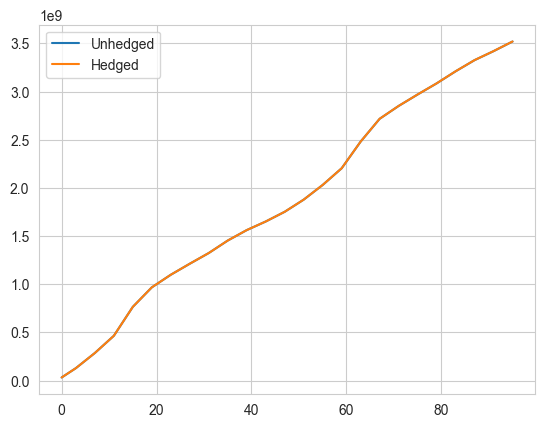

In [60]:
hist_sorted = fwd.sort_values("forward_month")

hist_sorted["cum_unhedged"] = hist_sorted["mean_unhedged"].cumsum()
hist_sorted["cum_hedged"] = hist_sorted["mean_hedged"].cumsum()

plt.plot(hist_sorted["cum_unhedged"], label="Unhedged")
plt.plot(hist_sorted["cum_hedged"], label="Hedged")
plt.legend()

In [55]:
fwd

,forward_month,strike_percentile,strike,premium_per_mwh,optimal_hedge_ratio,base_notional_mwh,mean_unhedged,mean_hedged,mean_profit_change,std_unhedged,std_hedged,var5_unhedged,var5_hedged,var5_improvement,es5_unhedged,es5_hedged,es5_improvement,prob_loss_unhedged,prob_loss_hedged,variance_reduction
0,1,25,40.795793,0.585820,0.999994,744663.234906,3.228351e+07,3.228495e+07,1436.561073,1.543161e+07,1.531385e+07,2.644721e+07,2.797083e+07,1.523620e+06,2.524621e+07,2.729800e+07,2.051793e+06,0.0000,0.0000,0.015203
1,1,50,43.583803,1.612467,0.999994,744663.234906,3.228351e+07,3.228746e+07,3954.128361,1.543161e+07,1.520218e+07,2.644721e+07,2.880621e+07,2.359009e+06,2.524621e+07,2.822278e+07,2.976569e+06,0.0000,0.0000,0.029514
2,1,60,44.642558,2.194059,0.999994,744663.234906,3.228351e+07,3.228889e+07,5380.318928,1.543161e+07,1.515870e+07,2.644721e+07,2.902672e+07,2.579512e+06,2.524621e+07,2.846868e+07,3.222469e+06,0.0000,0.0000,0.035057
3,1,75,46.357935,3.353168,0.999994,744663.234906,3.228351e+07,3.229173e+07,8222.712102,1.543161e+07,1.509432e+07,2.644721e+07,2.935165e+07,2.904448e+06,2.524621e+07,2.877709e+07,3.530875e+06,0.0000,0.0000,0.043237
4,2,25,49.629594,0.607284,0.999994,821653.274477,3.931873e+07,3.932038e+07,1643.162716,1.408204e+07,1.392151e+07,3.218260e+07,3.347514e+07,1.292535e+06,3.058637e+07,3.228822e+07,1.701849e+06,0.0000,0.0000,0.022669
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,23,75,32.310759,3.337295,0.677691,606015.224784,2.332179e+07,2.332630e+07,4513.489813,1.255924e+07,1.234325e+07,1.106915e+07,1.155585e+07,4.866956e+05,7.722486e+06,7.966577e+06,2.440913e+05,0.0000,0.0007,0.034100
92,24,25,29.742794,0.607631,0.999994,634970.118132,2.500152e+07,2.500280e+07,1270.554475,9.153704e+06,9.008163e+06,1.224218e+07,1.242339e+07,1.812097e+05,8.296156e+06,8.452627e+06,1.564705e+05,0.0002,0.0003,0.031546
93,24,50,32.473585,1.607817,0.902759,634970.118132,2.500152e+07,2.500456e+07,3035.038496,9.153704e+06,8.906885e+06,1.224218e+07,1.253074e+07,2.885540e+05,8.296156e+06,8.522068e+06,2.259124e+05,0.0002,0.0007,0.053201
94,24,60,33.489398,2.164747,0.885644,634970.118132,2.500152e+07,2.500553e+07,4008.873635,9.153704e+06,8.866749e+06,1.224218e+07,1.261182e+07,3.696375e+05,8.296156e+06,8.558587e+06,2.624313e+05,0.0002,0.0008,0.061714


<Axes: xlabel='profit_change', ylabel='hedged_profit'>

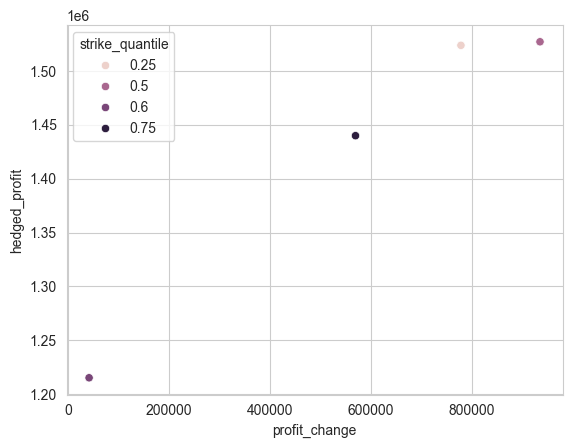

In [28]:
tradeoff = hist.groupby("strike_quantile").agg({
    "profit_change": "mean",
    "hedged_profit": es5
}).reset_index()

sns.scatterplot(
    data=tradeoff,
    x="profit_change",
    y="hedged_profit",
    hue="strike_quantile"
)

<Axes: xlabel='unhedged_profit', ylabel='Density'>

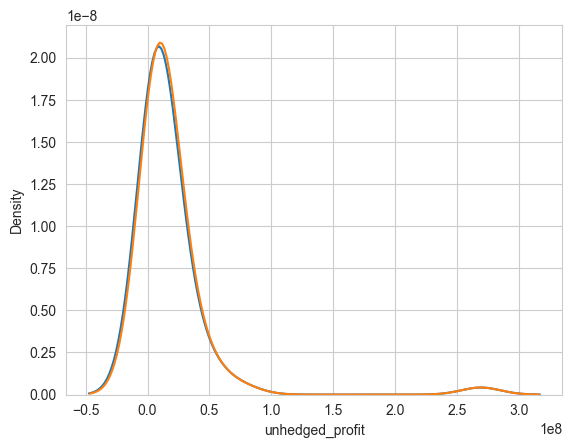

In [30]:
subset = hist[hist["strike_quantile"] == 0.5]

sns.kdeplot(subset["unhedged_profit"], label="Unhedged")
sns.kdeplot(subset["hedged_profit"], label="Hedged")

In [66]:
fwd

,forward_month,strike_percentile,strike,premium_per_mwh,optimal_hedge_ratio,base_notional_mwh,mean_unhedged,mean_hedged,mean_profit_change,std_unhedged,...,var5_unhedged,var5_hedged,var5_improvement,es5_unhedged,es5_hedged,es5_improvement,prob_loss_unhedged,prob_loss_hedged,variance_reduction,price_regime
0,1,25,40.795793,0.585820,0.999994,744663.234906,3.228351e+07,3.228495e+07,1436.561073,1.543161e+07,...,2.644721e+07,2.797083e+07,1.523620e+06,2.524621e+07,2.729800e+07,2.051793e+06,0.0000,0.0000,0.015203,Low
1,1,50,43.583803,1.612467,0.999994,744663.234906,3.228351e+07,3.228746e+07,3954.128361,1.543161e+07,...,2.644721e+07,2.880621e+07,2.359009e+06,2.524621e+07,2.822278e+07,2.976569e+06,0.0000,0.0000,0.029514,Low
2,1,60,44.642558,2.194059,0.999994,744663.234906,3.228351e+07,3.228889e+07,5380.318928,1.543161e+07,...,2.644721e+07,2.902672e+07,2.579512e+06,2.524621e+07,2.846868e+07,3.222469e+06,0.0000,0.0000,0.035057,Low
3,1,75,46.357935,3.353168,0.999994,744663.234906,3.228351e+07,3.229173e+07,8222.712102,1.543161e+07,...,2.644721e+07,2.935165e+07,2.904448e+06,2.524621e+07,2.877709e+07,3.530875e+06,0.0000,0.0000,0.043237,Low
4,2,25,49.629594,0.607284,0.999994,821653.274477,3.931873e+07,3.932038e+07,1643.162716,1.408204e+07,...,3.218260e+07,3.347514e+07,1.292535e+06,3.058637e+07,3.228822e+07,1.701849e+06,0.0000,0.0000,0.022669,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,23,75,32.310759,3.337295,0.677691,606015.224784,2.332179e+07,2.332630e+07,4513.489813,1.255924e+07,...,1.106915e+07,1.155585e+07,4.866956e+05,7.722486e+06,7.966577e+06,2.440913e+05,0.0000,0.0007,0.034100,Low
92,24,25,29.742794,0.607631,0.999994,634970.118132,2.500152e+07,2.500280e+07,1270.554475,9.153704e+06,...,1.224218e+07,1.242339e+07,1.812097e+05,8.296156e+06,8.452627e+06,1.564705e+05,0.0002,0.0003,0.031546,Low
93,24,50,32.473585,1.607817,0.902759,634970.118132,2.500152e+07,2.500456e+07,3035.038496,9.153704e+06,...,1.224218e+07,1.253074e+07,2.885540e+05,8.296156e+06,8.522068e+06,2.259124e+05,0.0002,0.0007,0.053201,Low
94,24,60,33.489398,2.164747,0.885644,634970.118132,2.500152e+07,2.500553e+07,4008.873635,9.153704e+06,...,1.224218e+07,1.261182e+07,3.696375e+05,8.296156e+06,8.558587e+06,2.624313e+05,0.0002,0.0008,0.061714,Low


In [63]:
fwd["price_regime"] = pd.cut(
    hist[""],
    bins=[0, 30, 50, 100],
    labels=["Low", "Medium", "High"]
)

fwd.groupby(["price_regime","strike_quantile"])["profit_change"].mean()

KeyError: 'strike_quantile'